In [9]:

# Set default graphics parameters
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}

In [10]:
library(ISLR) # load the ISLR package
data(Wage) # load the Wage dataset
help(Wage) # Wage and other data for a group of 3000 male workers in the Mid-Atlantic region
summary(Wage) # learn the structure of the dataset

      year           age                     maritl           race     
 Min.   :2003   Min.   :18.00   1. Never Married: 648   1. White:2480  
 1st Qu.:2004   1st Qu.:33.75   2. Married      :2074   2. Black: 293  
 Median :2006   Median :42.00   3. Widowed      :  19   3. Asian: 190  
 Mean   :2006   Mean   :42.41   4. Divorced     : 204   4. Other:  37  
 3rd Qu.:2008   3rd Qu.:51.00   5. Separated    :  55                  
 Max.   :2009   Max.   :80.00                                          
                                                                       
              education                     region               jobclass   
 1. < HS Grad      :268   2. Middle Atlantic   :3000   1. Industrial :1544  
 2. HS Grad        :971   1. New England       :   0   2. Information:1456  
 3. Some College   :650   3. East North Central:   0                        
 4. College Grad   :685   4. West North Central:   0                        
 5. Advanced Degree:426   5. South Atla

Wage                   package:ISLR                    R Documentation

_M_i_d-_A_t_l_a_n_t_i_c _W_a_g_e _D_a_t_a

_D_e_s_c_r_i_p_t_i_o_n:

     Wage and other data for a group of 3000 male workers in the
     Mid-Atlantic region.

_U_s_a_g_e:

     Wage
     
_F_o_r_m_a_t:

     A data frame with 3000 observations on the following 11 variables.

     'year' Year that wage information was recorded

     'age' Age of worker

     'maritl' A factor with levels '1. Never Married' '2. Married' '3.
          Widowed' '4. Divorced' and '5. Separated' indicating marital
          status

     'race' A factor with levels '1. White' '2. Black' '3. Asian' and
          '4. Other' indicating race

     'education' A factor with levels '1. < HS Grad' '2. HS Grad' '3.
          Some College' '4. College Grad' and '5. Advanced Degree'
          indicating education level

     'region' Region of the country (mid-atlantic only)

     'jobclass' A factor with l

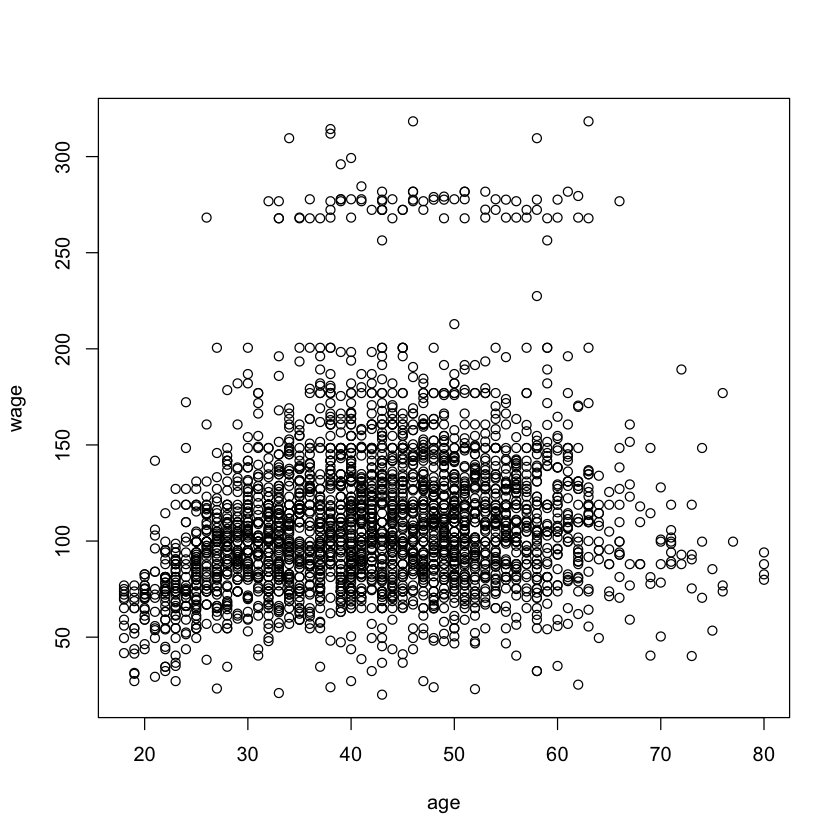

In [11]:
set_plot_defaults()


Wage$region<-NULL # no information in region variable, remove it, may cause errors in later models
age <- Wage$age
wage <- Wage$wage
plot(age,wage) # remember a few relationships/plots from the lecture

Polynomial regression

In [12]:
fit=lm(wage~poly(age,4),data=Wage) # learn the 4th degree polynomial age model with orthogonal polynomials
coef(summary(fit)) # show the model coefs

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),111.70361,0.7287409,153.283015,0.000000e+00
"poly(age, 4)1",447.06785,39.9147851,11.200558,1.484604e-28
"poly(age, 4)2",-478.31581,39.9147851,-11.983424,2.355831e-32
"poly(age, 4)3",125.52169,39.9147851,3.144742,1.678622e-03
"poly(age, 4)4",-77.91118,39.9147851,-1.951938,5.103865e-02


In [13]:
fit2=lm(wage~poly(age,4,raw=T),data=Wage) # learn the 4th degree polynomial age model with raw polynomials
coef(summary(fit2)) # the coefs and p-values change, later we will see it does not affect the fitted values

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-1.841542e+02,6.004038e+01,-3.067172,0.0021802539
"poly(age, 4, raw = T)1",2.124552e+01,5.886748e+00,3.609042,0.0003123618
"poly(age, 4, raw = T)2",-5.638593e-01,2.061083e-01,-2.735743,0.0062606446
"poly(age, 4, raw = T)3",6.810688e-03,3.065931e-03,2.221409,0.0263977518
"poly(age, 4, raw = T)4",-3.203830e-05,1.641359e-05,-1.951938,0.0510386498


In [14]:
fit2a=lm(wage~age+I(age^2)+I(age^3)+I(age^4),data=Wage) # explicitly calculate the higher-order terms, I inhibits the interpretation of ^ as a formula crossing/interaction operator, it would make no effect with the only variable age  
coef(fit2a) # no change from fit2

(Intercept)           age      I(age^2)      I(age^3)      I(age^4) 
-1.841542e+02  2.124552e+01 -5.638593e-01  6.810688e-03 -3.203830e-05

In [15]:
fit2b=lm(wage~cbind(age,age^2,age^3,age^4),data=Wage) # explicitly calculate the higher powers, store them into a data.frame
coef(fit2b) # no change from fit2 nor fit2a

(Intercept) cbind(age, age^2, age^3, age^4)age 
                     -1.841542e+02                       2.124552e+01 
   cbind(age, age^2, age^3, age^4)    cbind(age, age^2, age^3, age^4) 
                     -5.638593e-01                       6.810688e-03 
   cbind(age, age^2, age^3, age^4) 
                     -3.203830e-05

[1] 6.88658e-11

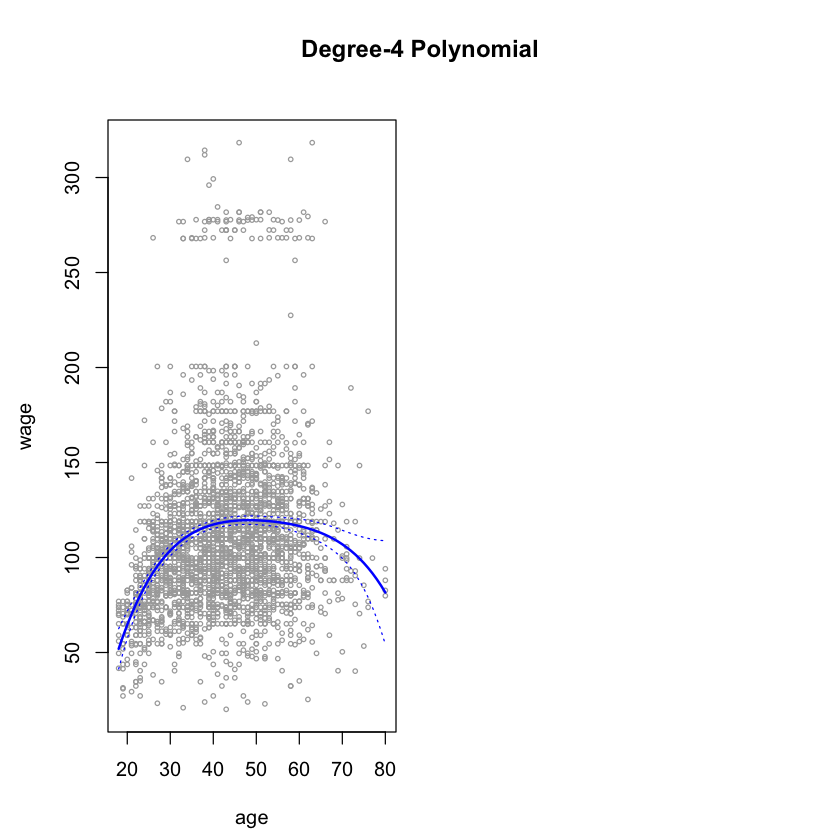

In [17]:
set_plot_defaults()

agelims=range(age) # compare all the models created above, create a regular grid of ages to test
age.grid=seq(from=agelims[1],to=agelims[2])
preds=predict(fit,newdata=list(age=age.grid),se=TRUE) # use the orthogonal polynomial model first
se.bands=cbind(preds$fit+2*preds$se.fit,preds$fit-2*preds$se.fit) # construct 95% confidence intervals
par(mfrow=c(1,2),mar=c(4.5,4.5,1,1),oma=c(0,0,4,0))
plot(age,wage,xlim=agelims,cex=.5,col="darkgrey")
title("Degree-4 Polynomial",outer=T)
lines(age.grid,preds$fit,lwd=2,col="blue")
matlines(age.grid,se.bands,lwd=1,col="blue",lty=3)
preds2=predict(fit2,newdata=list(age=age.grid),se=TRUE) # compare with the second fit (we have already found out that 2b and 2c must be identical)
max(abs(preds$fit-preds2$fit)) # there is nearly no difference between the predictions

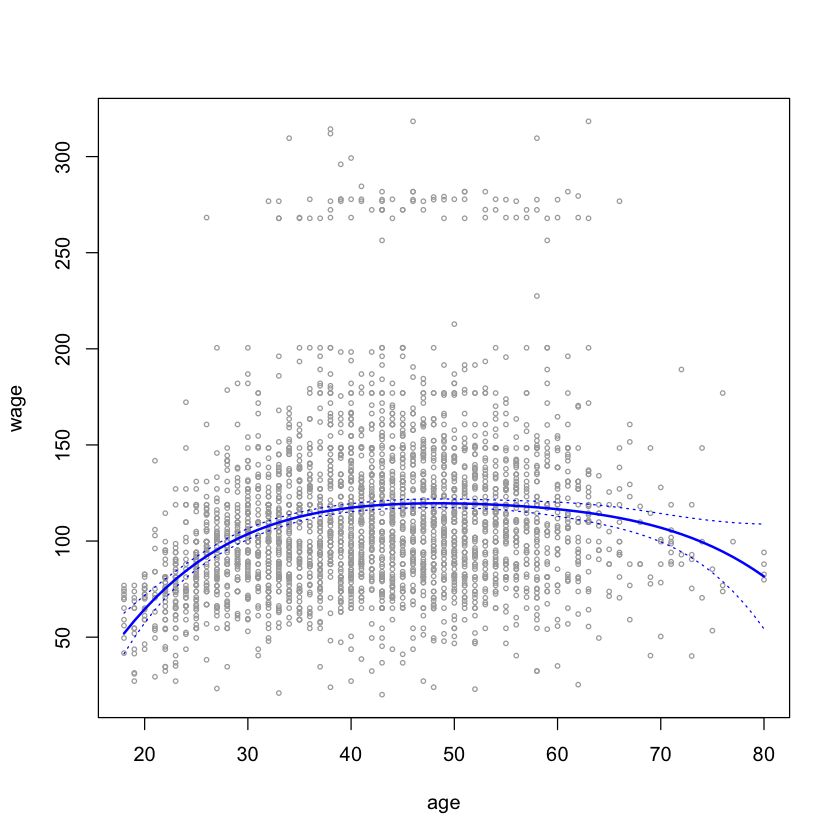

In [19]:
set_plot_defaults()
se2.bands=cbind(preds2$fit+2*preds2$se.fit,preds2$fit-2*preds2$se.fit) # construct 95% confidence intervals
plot(age,wage,xlim=agelims,cex=.5,col="darkgrey")
lines(age.grid,preds2$fit,lwd=2,col="blue")
matlines(age.grid,se2.bands,lwd=1,col="blue",lty=3)

In [20]:
fit.1=lm(wage~age,data=Wage)
fit.2=lm(wage~poly(age,2),data=Wage)
fit.3=lm(wage~poly(age,3),data=Wage)
fit.4=lm(wage~poly(age,4),data=Wage)
fit.5=lm(wage~poly(age,5),data=Wage)
anova(fit.1,fit.2,fit.3,fit.4,fit.5)

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2998,5022216,NA,NA,NA,NA
2,2997,4793430,1,228786.010,143.5931074,2.367734e-32
3,2996,4777674,1,15755.694,9.8887559,1.679213e-03
4,2995,4771604,1,6070.152,3.8098134,5.104623e-02
5,2994,4770322,1,1282.563,0.8049758,3.696820e-01


In [21]:
coef(summary(fit.5))


,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),111.70361,0.7287647,153.2780243,0.000000e+00
"poly(age, 5)1",447.06785,39.9160847,11.2001930,1.491111e-28
"poly(age, 5)2",-478.31581,39.9160847,-11.9830341,2.367734e-32
"poly(age, 5)3",125.52169,39.9160847,3.1446392,1.679213e-03
"poly(age, 5)4",-77.91118,39.9160847,-1.9518743,5.104623e-02
"poly(age, 5)5",-35.81289,39.9160847,-0.8972045,3.696820e-01


In [22]:
fit.1=lm(wage~education+age,data=Wage)
fit.2=lm(wage~education+poly(age,2),data=Wage)
fit.3=lm(wage~education+poly(age,3),data=Wage)
anova(fit.1,fit.2,fit.3)

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2994,3867992,NA,NA,NA,NA
2,2993,3725395,1,142597.10,114.696898,2.728971e-26
3,2992,3719809,1,5586.66,4.493588,3.410431e-02


In [25]:
gam1=lm(wage~ns(year,4)+ns(age,5)+education,data=Wage) # simple linear model when using bs() and ns()
gam.m3=gam(wage~s(year,4)+s(age,5)+education,data=Wage) # gam must be used to compile smoothing splines and/or local regression
par(mfrow=c(1,3))
plot(gam.m3, se=TRUE,col="blue") # show the gam model that uses smoothing splines (education is categorical and converted into dummy vars), demonstrate the individual components of the model

ERROR: Error in ns(year, 4): could not find function "ns"


In [24]:
gam.lo.i=gam(wage~lo(year,age,span=0.5)+education,data=Wage) # allow for interactions between year and age in local regression
plot(gam.lo.i) # plot the resulting two=dimensional surface, akima library is needed here

ERROR: Error in gam(wage ~ lo(year, age, span = 0.5) + education, data = Wage): could not find function "gam"


In [ ]:






nFolds <- 10
myFolds <- createFolds(seq(nrow(Wage)),nFolds)

pred <- rep(NA,nrow(Wage))
for (f in seq(nFolds)){
  gam.m2=gam(wage~year+s(age,5)+education,data=Wage[-myFolds[f][[1]],])
  pred[myFolds[f][[1]]] <- predict(gam.m2,Wage[myFolds[f][[1]],])
}
myRMSE(pred,Wage$wage) # the RMSE of the model that selects parameters based on p-values

ERROR: Error in createFolds(seq(nrow(Wage)), nFolds): could not find function "createFolds"
